In [1]:
import torch
import os
import statistics
import matplotlib.pyplot as plt

from pathlib import Path

from src.data_loader import load_synthetic_fire_data, load_processed_fire_data, load_processed_markdown_data, load_processed_rebel_data, load_rebel_sample
from src.evaluation.diversity import evaluate_semantic_similarity, evaluate_semantic_similarity_optimized

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

C:\Users\Matej\Documents\GitHub\MasterThesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Changed working directory to: C:\Users\Matej\Documents\GitHub\MasterThesis


In [2]:
synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_650_samples_4_examples.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_100_examples.json"
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

sentences = [sample.sentence for sample in synthetic_data]

scores = evaluate_semantic_similarity(sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 767.79it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Before encoding
After encoding
Before double loop
After double loop
Before sorting
After sorting
Average Pairwise Similarity: 0.249

Most similar non identical sentences:
Pair 1 - Score: 0.900, idx1: 157, idx2: 607
  A: The company merged with ABC corporation in 2020, resulting in a value of $100 million.
  B: The acquisition of ABC Ltd. by the company was completed in 2020, with a total value of $100 million.

Pair 2 - Score: 0.900, idx1: 474, idx2: 569
  A: Amazon Web Services is a subsidiary of Amazon.
  B: Amazon Web Services is a product of Amazon

Pair 3 - Score: 0.900, idx1: 110, idx2: 300
  A: Apple is located in California.
  B: Apple Inc. is located in California, USA.

Pair 4 - Score: 0.900, idx1: 300, idx2: 480
  A: Apple Inc. is located in California, USA.
  B: Apple is located in California.

Pair 5 - Score: 0.899, idx1: 94, idx2: 218
  A: The quantity of shares bought by the investor was 1000.
  B: The quantity of shares sold is 1000.

Pair 6 - Score: 0.899, idx1: 421, i

In [3]:
scores.fill_diagonal_(-1)   # So it doesn't match with itself
max_scores, _ = torch.max(scores, dim=1)
max_scores_list = max_scores.tolist()

In [4]:
duplicates = sum(1 for score in max_scores_list if score >= 0.98)
very_similar = sum(1 for score in max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in max_scores_list if score < 0.85)

print(f"Total Sentences: {len(sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(max_scores_list):.3f}")

Total Sentences: 650
Exact/Near Duplicates (Score > 0.98): 93 sentences
Very Similar Sentences (Score 0.85-0.98): 231 sentences
Different Sentences (Score < 0.85): 326 sentences
Avg. cosine similarity to closest match: 0.838
Median cosine similarity to closest match: 0.849


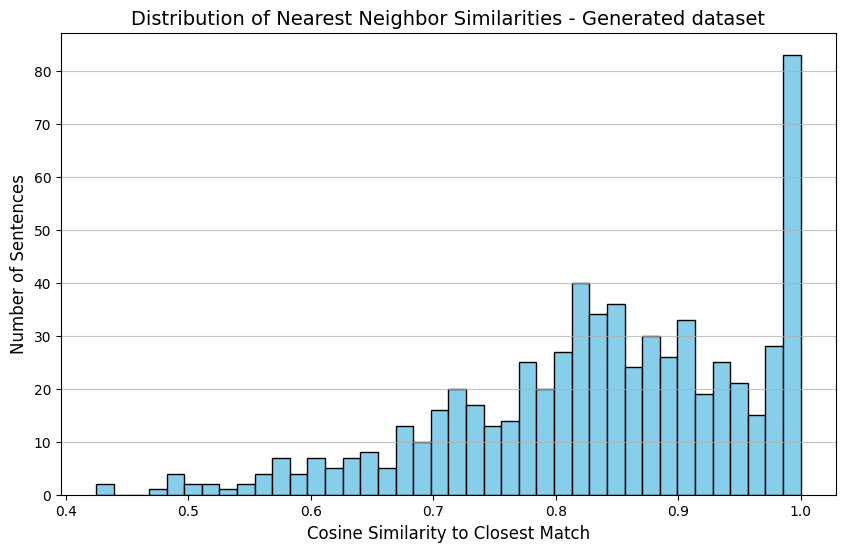

In [6]:
plt.figure(figsize=(10, 6))
plt.hist(max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Generated dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [2]:
fire_data_path = Path("data") / "02_processed" / "fire_train_processed.json"
fire_data = load_processed_fire_data(fire_data_path)

fire_sentences = [sample.sentence for sample in fire_data]

fire_scores = evaluate_semantic_similarity(fire_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 656.67it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Before encoding
After encoding
Before double loop
After double loop
Before sorting
After sorting
Average Pairwise Similarity: 0.144

Most similar non identical sentences:
Pair 1 - Score: 0.900, idx1: 1917, idx2: 2113
  A: PricewaterhouseCoopers LLP , the independent registered public accounting firm that audited the financial statements included in this Annual Report on Form 10 - K , has also audited the effectiveness of internal control over financial reporting as of December 31 , 2012 as stated in their report that appears on the following page .
  B: The effectiveness of the Company s internal control over financial reporting as of December 31 , 2012 , has been audited by PricewaterhouseCoopers LLP , an independent registered public accounting firm , as stated in their report which appears herein .

Pair 2 - Score: 0.898, idx1: 2002, idx2: 2003
  A: Compared to 2011 : Off - system sales revenue decreased by $ 40.1 million , or 39 percent , in 2012 as compared to 2011 , as a result o

In [3]:
fire_scores.fill_diagonal_(-1)   # So it doesn't match with itself
fire_max_scores, _ = torch.max(fire_scores, dim=1)
fire_max_scores_list = fire_max_scores.tolist()

In [4]:
duplicates = sum(1 for score in fire_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in fire_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in fire_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(fire_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(fire_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(fire_max_scores_list):.3f}")

Total Sentences: 2117
Exact/Near Duplicates (Score > 0.98): 19 sentences
Very Similar Sentences (Score 0.85-0.98): 99 sentences
Different Sentences (Score < 0.85): 1999 sentences
Avg. cosine similarity to closest match: 0.575
Median cosine similarity to closest match: 0.547


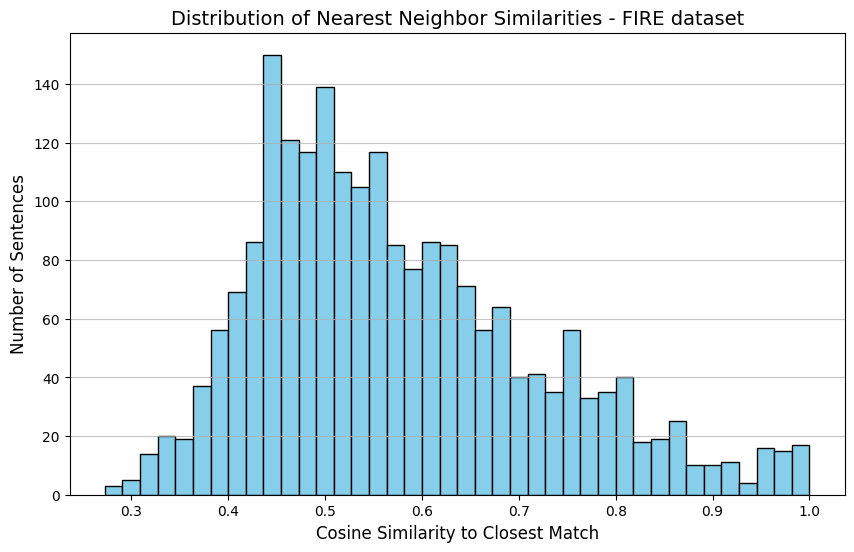

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(fire_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - FIRE dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [14]:
elekta = Path("data") / "02_processed" / "elekta_processed.json"
elekta_data = load_processed_markdown_data(elekta)

elekta_sentences = [sample.sentence for sample in elekta_data]

elekta_scores = evaluate_semantic_similarity(elekta_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 675.42it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.167

Most similar non identical sentences:
Pair 1 - Score: 0.896, idx1: 1589, idx2: 1613
  A: Cash flow from operating activities in relation to EBITDA.
  B: The operational cash conversion shows the relation between cash flow from operating activities and EBITDA.

Pair 2 - Score: 0.896, idx1: 614, idx2: 615
  A: The operating cash flow (cash flow from operating activities exclusive of change in working capital) Cash flow from operating activities amounted to SEK 2,114 M (1,869), an increase of SEK 245 M compared with the previous year.
  B: Cash flow from operating activities increased to SEK 1,964 M (1,858).

Pair 3 - Score: 0.894, idx1: 454, idx2: 917
  A: The guidelines for remuneration to the executive management were adopted by the AGM 2020 and will apply until the AGM 2024 at the latest.
  B: The guidelines for remuneration to the executive management, adopted by the AGM in 2020, are presented on page 28.

Pair 4 - Score: 0.892, idx1: 348, idx2: 61

In [15]:
elekta_scores.fill_diagonal_(-1)   # So it doesn't match with itself
elekta_max_scores, _ = torch.max(elekta_scores, dim=1)
elekta_max_scores_list = elekta_max_scores.tolist()

In [16]:
duplicates = sum(1 for score in elekta_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in elekta_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in elekta_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(elekta_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(elekta_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(elekta_max_scores_list):.3f}")

Total Sentences: 1976
Exact/Near Duplicates (Score > 0.98): 56 sentences
Very Similar Sentences (Score 0.85-0.98): 161 sentences
Different Sentences (Score < 0.85): 1759 sentences
Avg. cosine similarity to closest match: 0.700
Median cosine similarity to closest match: 0.696


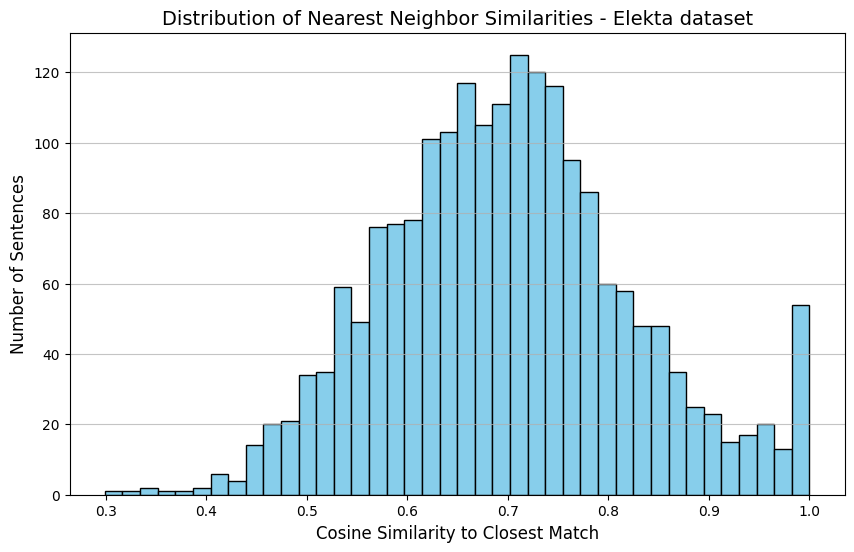

In [17]:
plt.figure(figsize=(10, 6))
plt.hist(elekta_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Elekta dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [18]:
vestas = Path("data") / "02_processed" / "vestas_processed.json"
vestas_data = load_processed_markdown_data(vestas)

vestas_sentences = [sample.sentence for sample in vestas_data]

vestas_scores = evaluate_semantic_similarity(vestas_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 544.57it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.170

Most similar non identical sentences:
Pair 1 - Score: 0.899, idx1: 864, idx2: 878
  A: Using sector-specific country averages allows impact assessment across many suppliers based on assumptions of water use and pollution.
  B: Using sector-country averages allows impact assessment across many suppliers, but is based on assumptions of e.g., land use and air pollution levels.

Pair 2 - Score: 0.899, idx1: 149, idx2: 189
  A: 1 Market forecasts adapted from Wood Mackenzie: Global wind power market outlook update: Q 2024.
  B: 4 Adapted from Wood Mackenzie: Global wind power market outlook update: Q 2024.

Pair 3 - Score: 0.896, idx1: 1478, idx2: 1574
  A: Waste quantities are tracked through weight slips, invoices, or statements from the waste recipients and reported quarterly.
  B: The quantity of waste reported is based on weight slips, invoices or statements received from the waste recipients for deliveries included in the accounting period.

Pair 4 

In [19]:
vestas_scores.fill_diagonal_(-1)   # So it doesn't match with itself
vestas_max_scores, _ = torch.max(vestas_scores, dim=1)
vestas_max_scores_list = vestas_max_scores.tolist()

In [20]:
duplicates = sum(1 for score in vestas_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in vestas_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in vestas_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(vestas_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(vestas_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(vestas_max_scores_list):.3f}")

Total Sentences: 3633
Exact/Near Duplicates (Score > 0.98): 121 sentences
Very Similar Sentences (Score 0.85-0.98): 231 sentences
Different Sentences (Score < 0.85): 3281 sentences
Avg. cosine similarity to closest match: 0.706
Median cosine similarity to closest match: 0.701


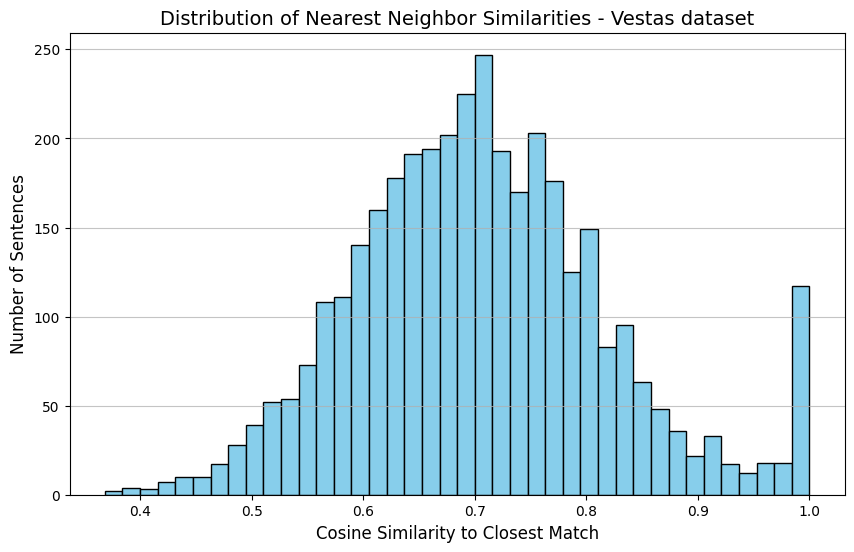

In [21]:
plt.figure(figsize=(10, 6))
plt.hist(vestas_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Vestas dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [2]:
rebel = Path("data") / "02_processed" / "rebel_processed.json"
rebel_data = load_rebel_sample(rebel)

rebel_sentences = [sample.sentence for sample in rebel_data]

rebel_scores = evaluate_semantic_similarity(rebel_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 769.61it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


KeyboardInterrupt: 

In [ ]:
rebel_scores.fill_diagonal_(-1)   # So it doesn't match with itself
rebel_max_scores, _ = torch.max(rebel_scores, dim=1)
rebel_max_scores_list = rebel_max_scores.tolist()

In [ ]:
duplicates = sum(1 for score in rebel_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in rebel_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in rebel_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(rebel_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(rebel_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(rebel_max_scores_list):.3f}")